## This notebook is for testing the ChebyshevInterpolant2D class

In [1]:
import numpy as np
from scipy.fft import dctn
from chebND.utils import chebyshev_nodes, find_significant_coeffs_1d, find_significant_coeffs_2d
from chebND.clenshaw import clenshaw_1d, clenshaw_2d
from chebND.interp2d import ChebyshevInterpolant2D
import matplotlib.pyplot as plt


from scipy.fft import dct

## Parallel Python Code Definitions

In [2]:
def compute_chebyshev_coefficients_2d(func_or_vals,Nx, Ny, ax, bx, ay, by, kind='dct'):
    """
    Compute the 2D Chebyshev coefficients of a function or discrete values
    over [ax, bx] × [ay, by].

    Parameters:
        func_or_vals : callable or 2D np.ndarray
            Either a function f(x, y), or a 2D array of values sampled at Chebyshev points.
        ax, bx : float
            Domain bounds in x-direction.
        ay, by : float
            Domain bounds in y-direction.
        Nx, Ny : int
            Number of Chebyshev points in x and y directions.
        kind : str
            Currently only 'dct' is supported, using DCT-I.

    Returns:
        coeffs : 2D np.ndarray
            Array of Chebyshev coefficients.
    """

    # Generate Chebyshev nodes in x and y
    x = chebyshev_nodes(Nx, ax, bx)
    y = chebyshev_nodes(Ny, ay, by)

    if callable(func_or_vals):
        X, Y = np.meshgrid(x, y, indexing='ij')
        vals = func_or_vals(X, Y)
    else:
        vals = np.asarray(func_or_vals)
        assert vals.shape == (Nx, Ny), "Input array shape must match (Nx, Ny)"

    if kind == 'dct':
        # Compute DCT-I in both dimensions
        coeffs = dctn(vals, type=2, norm=None)
        # Normalize to match Chebyshev projection
        coeffs *= 1 / ((Nx) * (Ny))
        coeffs[0, :] *= 0.5
        coeffs[:, 0] *= 0.5
    else:
        raise ValueError("Only 'dct' is supported for now.")

    return coeffs

In [3]:

def clenshaw_1D(coeffs, x,  k_max=None, a=-1.0, b=1.0):
    """
    Evaluate Chebyshev series at a single point x using Clenshaw's algorithm.
    
    Parameters:
        coeffs: array of Chebyshev coefficients
        x: point of evaluation in [a, b]
        a, b: domain bounds (default [-1, 1])
        k_max : int, optional
            Number of coefficients to use (truncate at this order).
            Defaults to len(coeffs).
    
    Returns:
        interpolated value at x
    """
    if k_max is None:
        k_max = len(coeffs)
    
    
    # Map x from [a, b] to [-1, 1]
    xt = (2.0 * x - a - b) / (b - a)
    
    b_k1 = 0.0
    b_k2 = 0.0
    for k in range(k_max-1, 0, -1):
        b_k = 2 * xt * b_k1 - b_k2 + coeffs[k]
        b_k2 = b_k1
        b_k1 = b_k
    return coeffs[0] + xt * b_k1 - b_k2


def clenshaw_2D(coeffs, x, y, NyMaxes = None, ax = -1., bx=1, ay=-1., by=1.):
    """
    Evaluate a 2D Chebyshev interpolant using the Clenshaw algorithm.

    Parameters:

        coeffs : 2D np.ndarray
            Matrix of Chebyshev coefficients [Nx, Ny].
        x, y : float
            Point to evaluate.
        Nx : int, optional
            Number of Chebyshev points in x-direction. If None, defaults to shape(coeffs)[0].
        Ny : int, optional
            Number of Chebyshev points in y-direction. If None, defaults to shape(coeffs)[1].
        ax, bx : float
            Domain bounds in x-direction.
        ay, by : float
            Domain bounds in y-direction.

    Returns:
        float
            Value of interpolant at (x, y)
    """
    if NyMaxes is None:
        NyMaxes = np.ones(coeffs.shape[0], dtype=np.int64) * coeffs.shape[1]

    # Map x, y from [ax, bx] and [ay, by] to [-1, 1]
    tx = (2 * x - (bx + ax)) / (bx - ax)
    ty = (2 * y - (by + ay)) / (by - ay)

    # Evaluate in y-direction first for each fixed x
    temp = np.array([clenshaw_1D(coeffs[i, :], ty,NyMaxes[i]) for i in range(NyMaxes.shape[0])])
    
    # Then evaluate resulting 1D Chebyshev series in x-direction
    return clenshaw_1D(temp, tx,NyMaxes.shape[0])

## Testing

In [17]:
# Define a smooth function
def f(x, y):
    return np.exp(-x**2 - y**2)

# Bounds and resolution
ax, bx = -2, 3
ay, by = -2, 1
Nx, Ny = 31, 30

# Generate Chebyshev nodes and compute coefficients
x_nodes = chebyshev_nodes(Nx, ax, bx)
y_nodes = chebyshev_nodes(Ny, ay, by)

X, Y = np.meshgrid(x_nodes, y_nodes, indexing='ij')
vals = f(X, Y)


In [18]:
vals2 = np.zeros((Nx, Ny))
for i, x in enumerate(x_nodes):
    for j, y in enumerate(y_nodes):
        vals2[i,j] = f(x, y)

vals.shape

(31, 30)

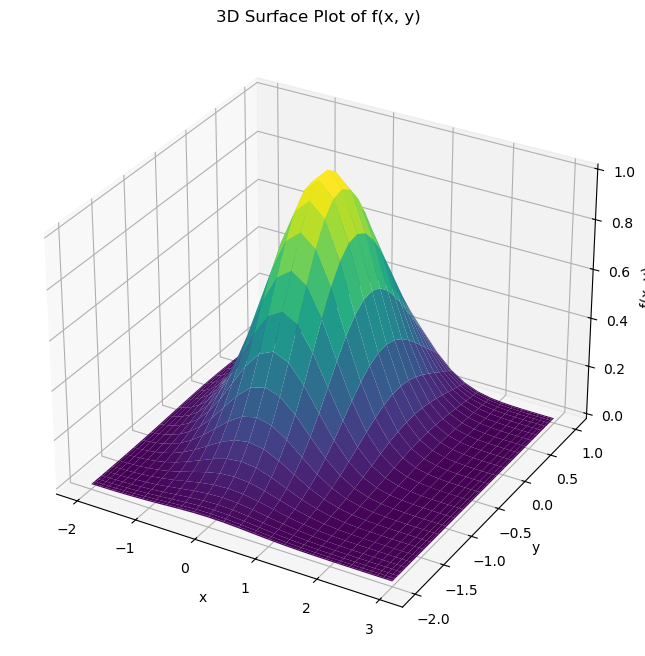

In [19]:
# Create a 3D plot of the function
fig = plt.figure(figsize=(10, 8))
ax1 = fig.add_subplot(111, projection='3d')
ax1.plot_surface(X, Y, vals, cmap='viridis', edgecolor='none')

ax1.set_xlabel('x')
ax1.set_ylabel('y')
ax1.set_zlabel('f(x, y)')
ax1.set_title('3D Surface Plot of f(x, y)')

plt.show()

In [20]:

# Compute coefficients
coeffs = compute_chebyshev_coefficients_2d(vals2,Nx, Ny, ax, bx, ay, by)

In [21]:
# Evaluate at some point
x_eval, y_eval = 1, -0.5
approx = clenshaw_2d(coeffs, x_eval, y_eval,NyMaxes=None, ax = ax,bx =bx,ay=ay,by=by)

# Compare to exact value
true_val = f(x_eval, y_eval)
error = abs(true_val - approx)

print(f"Approximation: {approx}")
print(f"True value:    {true_val}")
print(f"Absolute error: {error:.2e}")

Approximation: 0.28650479686058095
True value:    0.2865047968601901
Absolute error: 3.91e-13


In [22]:
interp = ChebyshevInterpolant2D(vals,Nx, Ny, ax, bx, ay, by)

approx2 = interp.evaluate(x_eval, y_eval)

# Compare to exact value
error2 = abs(true_val - approx2)

print(f"Approximation: {approx2}")
print(f"True value:    {true_val}")
print(f"Absolute error: {error2:.2e}")

# Compare to our other implementation
# Compare to exact value
error3 = abs(approx- approx2)
print(f"Implimentation 1: {approx}")
print(f"Error between implimentations: {error3:.2e}")

Approximation: 0.28650479686058095
True value:    0.2865047968601901
Absolute error: 3.91e-13
Implimentation 1: 0.28650479686058095
Error between implimentations: 0.00e+00


## Testing the optimisation proceedure

In [16]:
def clenshaw_1D_FindMaxCoeffs(coefficients, tol=1e-12):

    nymax = 0
    # Find the last significant coefficient
    n = len(coefficients)
    for i in range(n - 1, -1, -1):
        if abs(coefficients[i]) > tol:
            nymax = i
            break
    else:
        return 0  # If all coefficients are below tol, return 0

    return nymax


# Adaptive Clenshaw algorithm for 2D Chebyshev polynomial evaluation

def clenshaw_2D_FindMaxCoeffs(coefficients, rel_tol=1e-12):

    nx, ny = coefficients.shape
    tmp = np.zeros(nx)
    nyMax = np.zeros(nx)
    nxMax = 0

    # Determine adaptive tolerance based on largest coefficient
    max_coeff = np.max(np.abs(coefficients))
    tol = (max_coeff * rel_tol)/(nx + ny) if max_coeff > 0 else 0


    # Evaluate in the y-direction first
    for i in range(nx):
        nyMax[i] = clenshaw_1D_FindMaxCoeffs(coefficients[i, :], tol)

    nyMaxTrimmed = np.trim_zeros(nyMax)
    # Evaluate in the x-direction
    return nyMaxTrimmed.astype(np.int64)

In [17]:
rel_tol = 1e-3
myMax1 = clenshaw_2D_FindMaxCoeffs(coeffs, rel_tol=rel_tol)
myMax1

array([14,  0, 16,  0, 14,  0, 14,  0, 12,  0, 10,  0,  8,  0,  6,  0,  2])

In [18]:
myMax2 = find_significant_coeffs_2d(coeffs, rel_tol=rel_tol)
myMax2

array([18,  0, 18,  0, 16,  0, 16,  0, 14,  0, 12,  0, 10,  0,  8,  0,  6,
        0,  2])

In [12]:
# Evaluate at some point
x_eval, y_eval = 0.5, -0.5
approx = clenshaw_2d(coeffs, x_eval, y_eval,myMax2, ax = ax,bx =bx,ay=ay,by=by)

# Compare to exact value
true_val = f(x_eval, y_eval)
error = abs(true_val - approx)

print(f"Approximation: {approx}")
print(f"True value:    {true_val}")
print(f"Absolute error: {error:.2e}")

Approximation: 0.6065281633168339
True value:    0.6065306597126334
Absolute error: 2.50e-06


In [13]:
# Evaluate at some point
interp.optimize(rel_tol)
approx = interp.evaluate(x_eval, y_eval)

# Compare to exact value
true_val = f(x_eval, y_eval)
error = abs(true_val - approx)

print(f"Approximation: {approx}")
print(f"True value:    {true_val}")
print(f"Absolute error: {error:.2e}")
Nx2, Ny2 = interp.effective_grid()
print(f"Effective Grid: {Nx2} x {Ny2}")

Approximation: 0.6065281633168339
True value:    0.6065306597126334
Absolute error: 2.50e-06
Effective Grid: 19 x 18


In [15]:
interp2 = ChebyshevInterpolant2D(f,Nx2, Ny2, ax, bx, ay, by)

approx2 = interp.evaluate(x_eval, y_eval)

error = abs(true_val - approx2)

print(f"Approximation 2: {approx2}")
print(f"True value:    {true_val}")
print(f"Absolute error: {error:.2e}")
print(f"Esimtated Error: {interp2.absolute_error():.2e}")


Approximation 2: 0.6065281633168339
True value:    0.6065306597126334
Absolute error: 2.50e-06
Esimtated Error: 5.75e-05


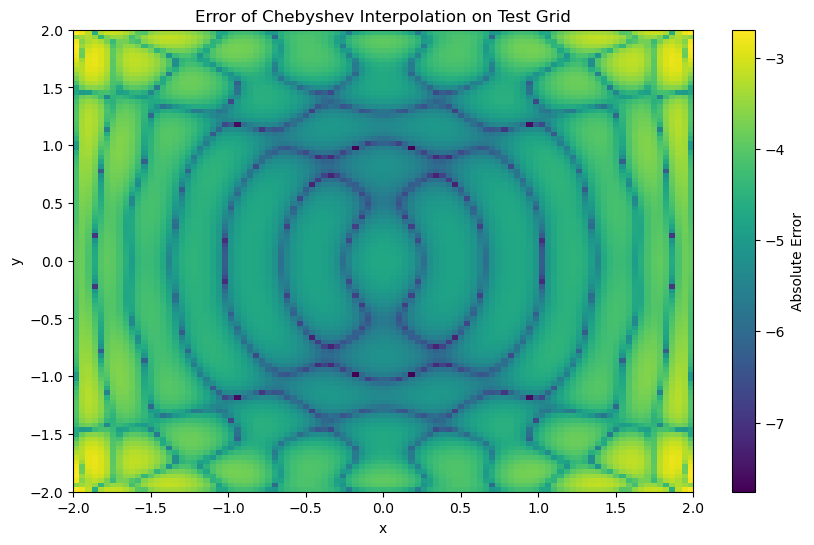

Max error on test grid: 2.02e-03
Median error on test grid 2.08e-05
Estimated Error: 3.10e-04
Relative Tolerance: 1.00e-03


In [20]:
# Want to calculate the error across an equally spaced test grid
x_test = np.linspace(ax + 0.1, bx-0.1, 100)
y_test = np.linspace(ay+0.1, by-0.1, 100)
X_test, Y_test = np.meshgrid(x_test, y_test, indexing='ij')
Z_test = f(X_test, Y_test)
# Evaluate the approximation on the test grid
rel_tol = 1e-3
interp2.optimize(rel_tol)
Z_approx = np.zeros_like(Z_test)
for i in range(X_test.shape[0]):
    for j in range(X_test.shape[1]):
        Z_approx[i, j] = interp2.evaluate(X_test[i, j], Y_test[i, j])
# Z_approx = clenshaw_2d(coeffs, X_test, Y_test,myMax1, ax = ax,bx =bx,ay=ay,by=by)
#Z_approx = interp.evaluate(x_test, y_test)
# Calculate the error on the test grid
Z_error = np.abs((Z_test - Z_approx)/Z_test)
# Plot the error
plt.figure(figsize=(10, 6))
plt.imshow(np.log10(Z_error), extent=(ax, bx, ay, by), origin='lower', aspect='auto', cmap='viridis')
plt.colorbar(label='Absolute Error')
plt.title('Error of Chebyshev Interpolation on Test Grid')
plt.xlabel('x')
plt.ylabel('y')
plt.show()

print(f"Max error on test grid: {np.max(Z_error):.2e}")
print(f"Median error on test grid {np.median(Z_error):.2e}")
print(f"Estimated Error: {interp2.relative_error():.2e}")
print(f"Relative Tolerance: {rel_tol:.2e}")

In [65]:
from scipy.linalg import svd

def compress_chebyshev_coeffs(C, tol=1e-12):
    U, S, Vh = svd(C, full_matrices=False)
    r = np.sum(S > tol * S[0])  # choose rank adaptively
    return U[:, :r], S[:r], Vh[:r, :]

def eval_reduced_interpolant(U, S, V, x, y):
    result = 0.0
    nx = U.shape[0]
    ny = V.shape[1]
    for k in range(len(S)):
        u_val = clenshaw_1d(U[:, k], x,nx, a=ax, b=bx)
        v_val = clenshaw_1d(V[k, :], y,ny,a=ay, b=by)
        result += S[k] * u_val * v_val
    return result

In [76]:
U, S, V = compress_chebyshev_coeffs(coeffs, tol=1e-10)

U.shape[0], V.shape[1], len(S)

(30, 30, 1)

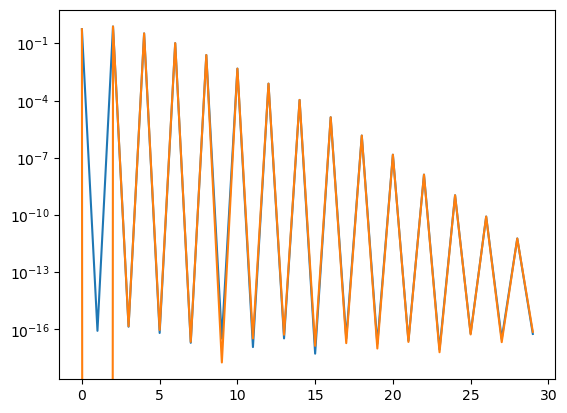

In [85]:
plt.plot(abs(U[:, 0]))
plt.plot(abs(V[0, :]))
plt.yscale('log')

In [78]:
# Evaluate at some point
x_eval, y_eval = 0.5, -0.5
approx = eval_reduced_interpolant(U, S, V, x_eval, y_eval)

# Compare to exact value
true_val = f(x_eval, y_eval)
error = abs(true_val - approx)

print(f"Approximation: {approx}")
print(f"True value:    {true_val}")
print(f"Absolute error: {error:.2e}")

Approximation: 0.6065306597125304
True value:    0.6065306597126334
Absolute error: 1.03e-13


Let's leave figuring out how to optimise the SVD evaluation until later. It's already a big improvement on its own and naturally lends itself to being precomputed in multiple directions pretty easily.

Focus on combining what we know into a simple to use interface like in the 1D case:

- A class that calculates the Coeffs
- Functions for the abs and rel errors
- Function to optimise based on the rel. tol
- Output the effective grid size
- Start testing that we recover the correct timings
- Set up the notebook to use this to compare with spline when computing FEW trajectories.
- Look into calculating PDs
- Want to save interpolant to a compressed file which can then be loaded